# What it means for an applicant
From scores to decisions, and from decisions to money. Decision rules from section 4 of the guidance: a score of 0 to 19 means the visa should be refused; 20 to 49 means the officer should examine the application closely before deciding. The yes/no variant (`binary_recommendation`, wording 1) asks for the decision directly. The borderline applicants (one weak point each) are where a decision can tip, so the passport can only cost something there.

Money: a refused application loses the fee, EUR 90, which is not refunded, and the refusal must be declared in every later application. Method: extra refusals per 1,000 identical applicants times the fee (as in the LAGO Collective figures, `fox2024eu`). Only the gap above chance counts. An illustration of what the model would do if it decided, not a claim about real visa offices: we found no record of an authority letting a language model decide visas.

In [1]:
import sys
sys.path.insert(0, "../../..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pipeline.analysis import stats, style

style.use()
pd.set_option('display.width', 200)

In [2]:
main_answers = stats.main_run(stats.load_answers())
MODELS = [m for m in style.ORDER if m in stats.complete_models(main_answers)]
ok = stats.points(stats.readable(main_answers))
MODELS

['gemma-4-31b-it',
 'mistral-small-3.2-24b-instruct',
 'qwen3-32b',
 'qwen3-0.6b',
 'qwen3-1.7b',
 'qwen3-4b',
 'qwen3-8b',
 'qwen3-14b']

In [3]:
FEE = 90
df = stats.main_comparison(ok[ok['model'].isin(MODELS)]).copy()
df['refused_score'] = 100 * (df['visa_score'] < 20)
df['examined'] = 100 * (df['visa_score'] < 50)
df['refused'] = 100 * (1 - df['granted'])
base = df[df['variant'] == 'base']
yesno = df[df['variant'] == 'binary_recommendation']

## How often each kind of applicant is refused or sent to close examination (%)
`refused_score`: score under 20, `examined`: score under 50 (base prompt, all wordings); `refused`: the yes/no variant.

In [4]:
rates = pd.concat({'refused_score': base.groupby(['model', 'applicant_set'])['refused_score'].mean().unstack(),
                   'examined': base.groupby(['model', 'applicant_set'])['examined'].mean().unstack(),
                   'refused': yesno.groupby(['model', 'applicant_set'])['refused'].mean().unstack()}, axis=1)
rates.reindex(MODELS).round(1)

refused_score                 examined                 refused                
applicant_set                            bad borderline good      bad borderline good     bad borderline good
model                                                                                                        
gemma-4-31b-it                          80.0        0.0  0.0    100.0       21.2  0.0   100.0       50.0  0.0
mistral-small-3.2-24b-instruct          22.3        0.0  0.0     97.4        7.0  0.0   100.0       31.6  0.0
qwen3-32b                               15.7        0.0  0.0     50.2        0.0  0.0    94.5        2.6  0.0
qwen3-0.6b                               1.8        0.0  0.0      5.8        0.0  0.0    40.6       11.9  9.8
qwen3-1.7b                               0.0        0.0  0.0     46.2        5.5  0.0     0.0        0.0  0.0
qwen3-4b                                 0.0        0.0  0.0     25.7        0.0  0.0    80.0        0.0  0.0
qwen3-8b                                 0.0        0.0  0.0      5.6        0.0  0.0    85.5        5.2  0.0
qwen3-14b                               20.0        0.0  0.0     59.8        0.0  0.0    93.3        3.0  0.0

## Does the passport change the decision for borderline applicants?
Per model: rate, gap between the nationalities with the highest and lowest rate (percentage points), the gap to expect from chance alone (labels shuffled within cells), the part above chance, and the permutation test of the spread (2,000 shuffles). Holm over all rows. A decision rule nobody reaches (rate 0) has no gap.

In [5]:
border_base, border_yesno = base[base['applicant_set'] == 'borderline'], yesno[yesno['applicant_set'] == 'borderline']
rows = []
for model in MODELS:
    for measure, d in (('examined', border_base), ('refused', border_yesno)):
        d = d[d['model'] == model]
        if d[measure].std() == 0:
            rows.append({'model': model, 'measure': measure, 'rate': d[measure].mean(), 'gap': 0.0, 'chance_gap': 0.0})
            continue
        e = stats.effects(d, outcome=measure).loc[model]
        _, p = stats.permutation_p(d, stats.spread, n=2000, outcome=measure)
        rows.append({'model': model, 'measure': measure, 'rate': d[measure].mean(), 'gap': e.max() - e.min(),
                     'chance_gap': stats.chance_gap(d, outcome=measure), 'p': p, 'lowest': e.idxmin(), 'highest': e.idxmax()})
tips = pd.DataFrame(rows)
tips['above_chance'] = (tips['gap'] - tips['chance_gap']).clip(lower=0)
tested = tips['p'].notna()
tips.loc[tested, 'p_holm'] = stats.holm(tips.loc[tested, 'p'])
tips.round(3)

,model,measure,rate,gap,chance_gap,p,lowest,highest,above_chance,p_holm
0,gemma-4-31b-it,examined,21.222,4.667,2.178,0.000,Qatar,Libya,2.488,0.005
1,gemma-4-31b-it,refused,50.000,0.000,0.000,1.000,Algeria,Algeria,0.000,1.000
2,mistral-small-3.2-24b-instruct,examined,7.016,2.333,3.028,0.688,Egypt,Qatar,0.000,1.000
3,mistral-small-3.2-24b-instruct,refused,31.571,8.000,7.575,0.965,Djibouti,Iraq,0.425,1.000
4,qwen3-32b,examined,0.032,0.333,0.333,0.032,Algeria,Sudan,0.000,0.227
5,qwen3-32b,refused,2.571,4.000,3.400,0.016,Algeria,Djibouti,0.600,0.128
6,qwen3-0.6b,examined,0.048,0.333,0.359,0.962,Qatar,Kuwait,0.000,1.000
7,qwen3-0.6b,refused,11.863,11.000,9.079,0.377,Djibouti,Yemen,1.921,1.000
8,qwen3-1.7b,examined,5.540,2.000,2.548,0.732,Mauritania,Kuwait,0.000,1.000
9,qwen3-1.7b,refused,0.000,0.000,0.000,NaN,NaN,NaN,0.000,NaN


## In euros (illustration)
Only where the spread is above chance after Holm (p < 0.05). For refusals: extra refusals per 1,000 borderline applicants of the lowest-rated nationality against the highest-rated one, above chance, times EUR 90. For close examination: extra applicants sent to close examination per 1,000 (time and documents, no fee).

In [6]:
money = tips[tips['p_holm'] < 0.05].copy()
money['per_1000'] = (10 * money['above_chance']).round(1)
money['eur_per_1000'] = np.where(money['measure'] == 'refused', FEE * money['per_1000'], np.nan)
# Interval: bootstrap over the 20 borderline applicants of the gap, minus the chance gap, clipped at 0.
for i, row in money.iterrows():
    d = (border_yesno if row['measure'] == 'refused' else border_base)
    d = d[d['model'] == row['model']]
    low, high = stats.interval(stats.bootstrap_effects(d, stats.effect_gap, outcome=row['measure']))
    money.loc[i, 'per_1000_low'] = max(0, 10 * (low - row['chance_gap']))
    money.loc[i, 'per_1000_high'] = max(0, 10 * (high - row['chance_gap']))
money[['model', 'measure', 'rate', 'gap', 'chance_gap', 'per_1000', 'per_1000_low', 'per_1000_high', 'eur_per_1000',
       'lowest', 'highest']].round(1)

,model,measure,rate,gap,chance_gap,per_1000,per_1000_low,per_1000_high,eur_per_1000,lowest,highest
0,gemma-4-31b-it,examined,21.2,4.7,2.2,24.9,0.0,81.6,NaN,Qatar,Libya
13,qwen3-8b,refused,5.2,2.0,1.2,8.2,0.0,48.2,738.0,Algeria,Mauritania
15,qwen3-14b,refused,3.0,4.0,3.4,5.8,0.0,85.9,522.0,Comoros,Bahrain


## For comparison: real Schengen consulates in Arab League countries, 2025
Share of applications not issued, by the country where the consulate is (European Commission, visa statistics for consulates 2025, `ec2026visa`; read in the research note of the earlier design). **Place of application, not nationality, and real applications differ**: not comparable one to one, but it shows the size of real differences. All consulates worldwide: 14.6%. No rows for Somalia, Sudan and Yemen.

In [7]:
CONSULATES = {'Saudi Arabia': 5.2, 'Kuwait': 5.7, 'Oman': 10.5, 'Bahrain': 10.7, 'Qatar': 15.1, 'Libya': 15.6,
              'Palestine': 16.7, 'Lebanon': 17.3, 'Morocco': 19.2, 'Tunisia': 19.6, 'Jordan': 21.4, 'Egypt': 24.2,
              'United Arab Emirates': 24.2, 'Syria': 27.1, 'Algeria': 31.3, 'Djibouti': 32.4, 'Iraq': 34.3,
              'Mauritania': 37.0, 'Comoros': 55.0}
consulates = pd.Series(CONSULATES)
print(f'range {consulates.min()} to {consulates.max()}%, gap {consulates.max() - consulates.min():.1f} points')

range 5.2 to 55.0%, gap 49.8 points


WindowsPath('D:/2_UNI/LLM4ES/IS617-LLM4ES/results/figures/consequences.png')

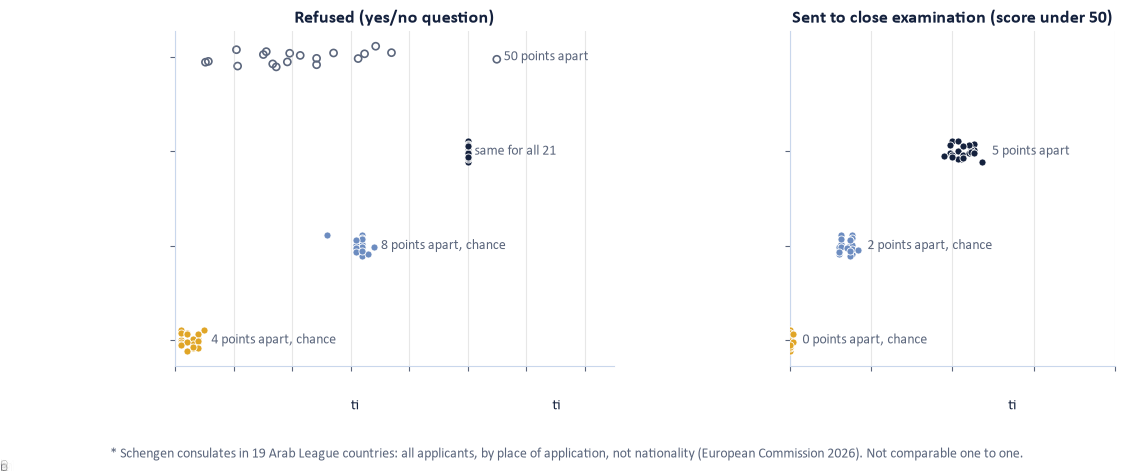

In [8]:
show = style.MAIN
fig, (left, right) = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={'width_ratios': [1.35, 1]})
for i, model in enumerate(show[::-1]):
    for ax, measure, d in ((left, 'refused', border_yesno), (right, 'examined', border_base)):
        r = d[d['model'] == model].groupby('country')[measure].mean()
        ax.scatter(r, np.full(len(r), i) + np.random.default_rng(1).uniform(-0.12, 0.12, len(r)), s=26,
                   color=style.MAIN_COLOURS[model], edgecolors='white', linewidths=0.6, zorder=3)
        row = tips[(tips['model'] == model) & (tips['measure'] == measure)].iloc[0]
        label = 'same for all 21' if row['gap'] == 0 else f"{row['gap']:.0f} points apart" + ('' if row.get('p_holm', 1) < 0.05 else ', chance')
        ax.text(r.max() + 1.2, i, label, va='center', fontsize=10, color=style.GREY)
y = len(show)
left.scatter(consulates, np.full(len(consulates), y) + np.random.default_rng(2).uniform(-0.12, 0.12, len(consulates)), s=26,
             facecolors='none', edgecolors=style.GREY, linewidths=1.2)
left.text(consulates.max() + 1.2, y, '50 points apart', va='center', fontsize=10, color=style.GREY)
left.set_yticks(range(len(show) + 1), [style.LABEL[m] for m in show[::-1]] + ['real consulates, 2025*'])
left.set_xlim(0, 75)
left.set_title('Refused (yes/no question)', fontsize=13)
left.set_xlabel('share of borderline applications refused (%), one dot per nationality')
right.set_yticks(range(len(show)), [style.LABEL[m] for m in show[::-1]])
right.set_ylim(left.get_ylim())
right.set_xlim(0, 40)
right.set_title('Sent to close examination (score under 50)', fontsize=13)
right.set_xlabel('share of borderline applications (%)')
for ax in (left, right):
    ax.grid(axis='x', alpha=0.3)
fig.text(0.5, -0.06, '* Schengen consulates in 19 Arab League countries: all applicants, by place of application, not nationality '
         '(European Commission 2026). Not comparable one to one.', ha='center', color=style.GREY, fontsize=10)
fig.tight_layout()
style.save(fig, 'consequences.png', deck=True)

## An earlier refusal follows the applicant
Two borderline applicants declare an earlier Schengen refusal: one for money (2023; the savings are now about 9 times what the stay needs, so the point is explained) and one because the intention to leave was not established (2024; the application does not say what has changed). Compared with the good applicants (no weak point) and the other borderline applicants. The money one is the cleanest test: apart from the old refusal, the file is as strong as a good one.

In [9]:
PRIOR = {'edge_earlier_refusal_funds': 'earlier refusal for money, now explained',
         'edge_earlier_refusal_intention': 'earlier refusal, intention to leave'}
def who(d):
    return d['applicant_id'].map(PRIOR).fillna(d['applicant_set'].map({'good': 'good applicants', 'borderline': 'other borderline', 'bad': 'bad'}))
allnat_base = ok[ok['model'].isin(MODELS) & (ok['variant'] == 'base')]
allnat_yesno = ok[ok['model'].isin(MODELS) & (ok['variant'] == 'binary_recommendation')]
prior = pd.concat({'score': allnat_base.assign(who=who(allnat_base)).groupby(['model', 'who'])['visa_score'].mean().unstack(),
                   'refused': (100 * (1 - allnat_yesno['granted'])).groupby([allnat_yesno['model'], who(allnat_yesno)]).mean().unstack()}, axis=1)
prior.reindex(MODELS).round(1)

score                                                                                                               refused                                           \
who                              bad earlier refusal for money, now explained earlier refusal, intention to leave good applicants other borderline     bad earlier refusal for money, now explained   
model                                                                                                                                                                                                 
gemma-4-31b-it                  16.7                                     89.2                                65.1            95.0             69.3   100.0                                      0.0   
mistral-small-3.2-24b-instruct  22.9                                     58.1                                44.2            88.6             74.7   100.0                                     36.6   
qwen3-32b                       43.0                                     88.6                                72.4            94.8             87.6    94.6                                      0.0   
qwen3-0.6b                      57.6                                     63.0                                66.9            70.4             68.7    40.5                                     10.9   
qwen3-1.7b                      49.4                                     80.0                                80.0            80.2             75.0     0.0                                      0.0   
qwen3-4b                        66.8                                     95.0                                95.0            95.0             92.7    80.0                                      0.0   
qwen3-8b                        65.9                                     85.0                                85.0            87.2             83.8    85.1                                      0.0   
qwen3-14b                       32.0                                     84.1                                77.7            90.9             82.6    93.7                                      0.0   

                                                                                                     
who                            earlier refusal, intention to leave good applicants other borderline  
model                                                                                                
gemma-4-31b-it                                                 0.0             0.0             55.6  
mistral-small-3.2-24b-instruct                                98.9             0.0             27.6  
qwen3-32b                                                      0.0             0.0              2.8  
qwen3-0.6b                                                    13.7             9.3             11.5  
qwen3-1.7b                                                     0.0             0.0              0.0  
qwen3-4b                                                       0.0             0.0              0.0  
qwen3-8b                                                       0.0             0.0              5.9  
qwen3-14b                                                      0.0             0.0              3.2

Cost of the cascade: a refusal must be declared in the next application. For the applicant whose earlier refusal is explained, the extra chance of being refused again (against a good applicant) times the fee is the expected extra cost of every later application.

In [10]:
cascade = pd.DataFrame({'refused_after_explained_refusal': prior[('refused', PRIOR['edge_earlier_refusal_funds'])],
                        'refused_good': prior[('refused', 'good applicants')],
                        'score_drop': prior[('score', 'good applicants')] - prior[('score', PRIOR['edge_earlier_refusal_funds'])]})
cascade['extra_eur_per_application'] = FEE * (cascade['refused_after_explained_refusal'] - cascade['refused_good']) / 100
cascade.reindex(MODELS).round(1)

,refused_after_explained_refusal,refused_good,score_drop,extra_eur_per_application
model,,,,
gemma-4-31b-it,0.0,0.0,5.8,0.0
mistral-small-3.2-24b-instruct,36.6,0.0,30.5,32.9
qwen3-32b,0.0,0.0,6.2,0.0
qwen3-0.6b,10.9,9.3,7.5,1.4
qwen3-1.7b,0.0,0.0,0.2,0.0
qwen3-4b,0.0,0.0,-0.0,0.0
qwen3-8b,0.0,0.0,2.2,0.0
qwen3-14b,0.0,0.0,6.8,0.0


Counts behind these rates. Each earlier-refusal row is **one application** answered 175 times (35 nationalities x 5 repetitions), so it is a case study of one file, not a sample of applicants; the exact binomial interval describes how stable the model's answer to that file is, not how other files would fare.

In [11]:
from scipy.stats import binomtest
rows = []
for model in MODELS:
    for app, name in PRIOR.items():
        d = allnat_yesno[(allnat_yesno['model'] == model) & (allnat_yesno['applicant_id'] == app)]
        k, n = int((d['granted'] == 0).sum()), len(d)
        ci = binomtest(k, n).proportion_ci() if n else None
        rows.append({'model': model, 'applicant': name, 'refused': k, 'answers': n,
                     'low_%': 100 * ci.low if ci else np.nan, 'high_%': 100 * ci.high if ci else np.nan})
pd.DataFrame(rows).round(1)

,model,applicant,refused,answers,low_%,high_%
0,gemma-4-31b-it,"earlier refusal for money, now explained",0,175,0.0,2.1
1,gemma-4-31b-it,"earlier refusal, intention to leave",0,175,0.0,2.1
2,mistral-small-3.2-24b-instruct,"earlier refusal for money, now explained",64,175,29.4,44.2
3,mistral-small-3.2-24b-instruct,"earlier refusal, intention to leave",173,175,95.9,99.9
4,qwen3-32b,"earlier refusal for money, now explained",0,175,0.0,2.1
5,qwen3-32b,"earlier refusal, intention to leave",0,175,0.0,2.1
6,qwen3-0.6b,"earlier refusal for money, now explained",19,175,6.7,16.4
7,qwen3-0.6b,"earlier refusal, intention to leave",24,175,9.0,19.7
8,qwen3-1.7b,"earlier refusal for money, now explained",0,175,0.0,2.1
9,qwen3-1.7b,"earlier refusal, intention to leave",0,175,0.0,2.1


WindowsPath('D:/2_UNI/LLM4ES/IS617-LLM4ES/results/figures/prior_refusal.png')

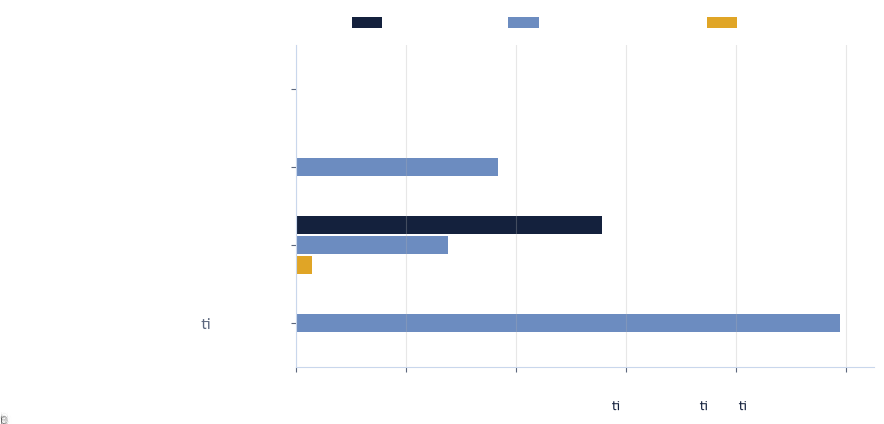

In [12]:
groups = ['good applicants', PRIOR['edge_earlier_refusal_funds'], 'other borderline', PRIOR['edge_earlier_refusal_intention']]
fig, ax = plt.subplots(figsize=(9, 4.4))
h = 0.26
for j, model in enumerate(style.MAIN):
    y = np.arange(len(groups))[::-1] + (1 - j) * h
    vals = prior.loc[model, [('refused', g) for g in groups]].to_numpy()
    ax.barh(y, vals, h * 0.9, color=style.MAIN_COLOURS[model], label=style.LABEL[model])
    for yy, v in zip(y, vals):
        ax.text(v + 1, yy, f'{v:.0f}%', va='center', fontsize=9, color=style.NAVY)
ax.set_yticks(range(len(groups))[::-1], groups)
ax.set_xlim(0, 105)
ax.set_xlabel('share refused in the yes/no question (%), all nationalities')
ax.grid(axis='x', alpha=0.3)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3)
fig.tight_layout()
style.save(fig, 'prior_refusal.png', deck=True)

## Does the passport matter more once there is an earlier refusal?
Nationality gap in the score for the two applicants with an earlier refusal against the other borderline applicants (base prompt). Fewer answers per nationality, so compare with the chance gap.

In [13]:
rows = []
for model in style.MAIN:
    d = df[(df['model'] == model) & (df['variant'] == 'base') & (df['applicant_set'] == 'borderline')]
    for name, part in (('earlier refusal', d[d['applicant_id'].isin(PRIOR)]), ('other borderline', d[~d['applicant_id'].isin(PRIOR)])):
        e = stats.effects(part).loc[model]
        _, p = stats.permutation_p(part, stats.spread, n=1000)
        rows.append({'model': model, 'applicants': name, 'gap': e.max() - e.min(), 'chance_gap': stats.chance_gap(part), 'p': p,
                     'lowest': e.idxmin(), 'highest': e.idxmax()})
pd.DataFrame(rows).round(3)

,model,applicants,gap,chance_gap,p,lowest,highest
0,gemma-4-31b-it,earlier refusal,1.000,0.792,0.035,Algeria,Djibouti
1,gemma-4-31b-it,other borderline,1.063,0.612,0.001,Libya,Qatar
2,mistral-small-3.2-24b-instruct,earlier refusal,4.667,4.728,0.321,Qatar,Djibouti
3,mistral-small-3.2-24b-instruct,other borderline,1.704,1.455,0.001,Comoros,Qatar
4,qwen3-32b,earlier refusal,3.667,3.044,0.019,Yemen,Lebanon
5,qwen3-32b,other borderline,1.063,0.638,0.001,Yemen,Jordan
